<center><h1> ETI195 - etica para Ciencia de Datos y Estadistica </h1><center>
<center><h2> Taller Sumativo 3: Modelos interpretables y xAI <h2><center>  




**Integrantes del grupo:**

1. Sergio Andres Hernandez Salgado
2. Marco Antonio Ramirez Gaete
3. Reinaldo Rodrigo Oliva Morales
4. Juan Tomas Jose Lepivil Vigueras

**Dataset:** CASEN 2024 preprocesado — variable objetivo `pobreza_multi`.

# `Instrucciones generales`

Esta es la parte III del proyecto, considera ultizar tus resultados anteriores
y reciclar el codigo anterior.

## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a traves de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografia y redaccion, con respuestas en tono academico.
- No respondan con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografia si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de codigo y consulten sus dudas con sus ayudantes.

- **Lean la rubrica antes de hacer su tarea.**

## `Integridad academica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad academica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el codigo.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citacion de codigo externo, no duden en preguntar. Pueden usar libremente los codigos de los talleres formativos. <3


In [2]:
# Coloque aqui todas las importaciones que considere necesarias
from transformers import pipeline
from lime.lime_text import LimeTextExplainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)
pd.set_option("display.max_colwidth", 120)

c:\Users\USUARIO\OneDrive\Desktop\Taller_ETI195_Casen2024\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Parte 1: Interpretabilidad local con LIME

## Motivacion

Un modelo de clasificacion de texto puede tener buen desempeño agregado y aun asi fallar sistematicamente ante ciertos tipos de lenguaje: eufemismos, tecnicismos, formas indirectas de comunicar una noticia, o lenguaje cargado politicamente. Estas fallas suelen ser invisibles si solo miramos metricas globales o si confiamos ciegamente en el sistema. LIME permite explorar una prediccion individual y preguntar: ¿que palabras llevaron al modelo a decidir esto? Esto es especialmente relevante cuando el texto que se clasifica admite multiples interpretaciones, tiene una carga social relevante y, en definitiva, forma parte de un sistema con consecuencias reales sobre las personas.

En esta parte van a diseñar un pequeño experimento: eligen un contexto de riesgo asociado a su proyecto, construyen frases que pongan a prueba ese riesgo especifico, y usan LIME para ver si el modelo efectivamente falla (o no) de la manera que hipotetizaron.

## Parte 1.1: Contexto

Lo primero que deben hacer es definir el contexto de su analisis. Dependiendo del proyecto que su grupo haya escogido, elijan un escenario en el que un sistema sociotecnico relacionado con su dataset tuviera que clasificar lenguaje, y en el que un error de clasificacion tuviera una consecuencia concreta. Por ejemplo:

- **CIRI**: un sistema que clasifica declaraciones oficiales de gobiernos para detectar lenguaje que minimiza o niega violaciones a los derechos humanos.

- **Breast Cancer**: un sistema que analiza como se comunica un diagnostico a pacientes.

- **CASEN**: un sistema que clasifica comunicaciones de resultados de ayudas sociales.

**Responder:**

0. Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

1. Describan el escenario de riesgo que eligieron: ¿que tipo de frases van a analizar y por que esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.

## Parte 1.2: Aplicacion de LIME

1. Carguen el modelo BETO de analisis de sentimientos.

2. Obtengan la prediccion del modelo para cada frase y comparen los resultados con su hipotesis de 1.1: ¿se cumplio lo que esperaban?

3. Apliquen LIME para obtener la explicacion local de al menos 5 frases, priorizando aquellas donde el modelo se comporto de forma inesperada o donde identifiquen un problema etico. Si no encuentran ningun problema, justifiquen esa conclusion. Para cada una, visualicen las contribuciones de cada palabra mediante un grafico de barras.

4. Interpreten los resultados: ¿que palabras estan dominando cada prediccion? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema etico o social en los resultados?

# Respuestas Parte 1

## Parte 1.1: Contexto

### 0. ¿Que son XAI, LIME y SHAP?

**XAI** (inteligencia artificial explicable) agrupa tecnicas para entender por que un modelo toma una decision. Es util con modelos de "caja negra", donde no vemos que pasa por dentro. La idea es poder revisar si el modelo decide por buenas razones o si tiene sesgos (Molnar, 2022).

**LIME** explica una prediccion a la vez. En texto, va quitando palabras de la frase y mira como cambia la respuesta del modelo. Asi estima que palabras pesaron mas en esa decision (Ribeiro et al., 2016).

**SHAP** tambien mide cuanto aporta cada variable a una prediccion, pero con una base matematica mas solida (los valores de Shapley). Ademas, permite ver tanto un caso individual como el comportamiento general del modelo (Lundberg & Lee, 2017).

En este taller usamos LIME para ver en que palabras se fija un modelo de sentimiento (BETO) y SHAP para entender el Random Forest que predice pobreza multidimensional.

### 1. Escenario de riesgo

Imaginamos que una institucion que entrega ayudas sociales usa un modelo para clasificar sus mensajes a los hogares como **negativos, neutros o positivos**. Los mensajes negativos (por ejemplo, un rechazo) se derivan a un equipo que llama al hogar para explicarle el resultado y como apelar.

El riesgo es que el modelo se equivoque:
- Si un **rechazo** se clasifica como positivo o neutro, el hogar no recibe ayuda para apelar.
- Si una **buena noticia** con palabras como "pobreza" o "vulnerabilidad" se clasifica como negativa, se asocia la pobreza con algo negativo y se gastan recursos de seguimiento.

Probamos 14 frases agrupadas asi:

| Grupo | Que queremos ver | Frases |
|---|---|---|
| Control | Mensajes claros, para ver que el modelo funcione en lo basico | 0, 1 |
| A. Tono amable con mala noticia | ¿El modelo se deja llevar por "nos complace" o "buenas noticias"? | 2, 7 |
| B. Palabras de carencia | ¿"Pobreza", "dificil" o "vulnerabilidad" hacen que una buena noticia parezca negativa? | 3, 5, 9 |
| C. Lenguaje administrativo o mixto | Tecnicismos, negaciones y aprobaciones parciales | 4, 6, 8 |
| D. Distinto destinatario | El mismo mensaje dirigido a una vecina chilena, inmigrante, mapuche o de Las Condes. Deberia dar lo mismo. | 10–13 |

Nuestra hipotesis general es que **el modelo se fija mas en el tono que en lo que realmente significa el mensaje para el hogar**. En la tabla, `hipotesis` es lo que creemos que dira el modelo y `deseada` es lo que deberia decir.

In [3]:
frases = pd.DataFrame([
    # Controles
    ("Control", "Nos alegra comunicarle que su solicitud de subsidio habitacional ha sido aprobada.", "POS", "POS"),
    ("Control", "Lamentamos informarle que su solicitud de apoyo economico ha sido rechazada.", "NEG", "NEG"),
    # A, B y C
    ("A", "Nos complace informarle que, lamentablemente, usted no cumple los requisitos para recibir el beneficio.", "POS", "NEG"),
    ("B", "Aunque su familia atraviesa una situacion economica dificil, su solicitud de ayuda ha sido aprobada.", "NEG", "POS"),
    ("C", "Su postulacion ha sido declarada inadmisible por incumplimiento de los requisitos establecidos.", "NEU", "NEG"),
    ("B", "Su hogar presenta condiciones de pobreza multidimensional y registra carencias en educacion y vivienda.", "NEG", "NEU"),
    ("C", "Su solicitud no ha sido rechazada, pero todavia se encuentra en evaluacion.", "NEG", "NEU"),
    ("A", "Buenas noticias: este mes no recibira el subsidio que esperaba.", "POS", "NEG"),
    ("C", "Su beneficio ha sido aprobado, aunque el monto asignado sera inferior al solicitado.", "POS", "POS"),
    ("B", "La evaluacion socioeconomica determino que su hogar pertenece a un grupo de alta vulnerabilidad.", "NEG", "POS"),
    # D. Marcadores de identidad (mismo contenido, distinto destinatario)
    ("D", "Estimada vecina chilena, su solicitud de apoyo para la vivienda ha sido aprobada.", "POS", "POS"),
    ("D", "Estimada vecina inmigrante, su solicitud de apoyo para la vivienda ha sido aprobada.", "POS", "POS"),
    ("D", "Estimada vecina mapuche, su solicitud de apoyo para la vivienda ha sido aprobada.", "POS", "POS"),
    ("D", "Estimada vecina de Las Condes, su solicitud de apoyo para la vivienda ha sido aprobada.", "POS", "POS"),
], columns=["familia", "frase", "hipotesis", "deseada"])

print("Cantidad de frases:", len(frases))
frases

Cantidad de frases: 14


,familia,frase,hipotesis,deseada
0,Control,Nos alegra comunicarle que su solicitud de subsidio habitacional ha sido aprobada.,POS,POS
1,Control,Lamentamos informarle que su solicitud de apoyo economico ha sido rechazada.,NEG,NEG
2,A,"Nos complace informarle que, lamentablemente, usted no cumple los requisitos para recibir el beneficio.",POS,NEG
3,B,"Aunque su familia atraviesa una situacion economica dificil, su solicitud de ayuda ha sido aprobada.",NEG,POS
4,C,Su postulacion ha sido declarada inadmisible por incumplimiento de los requisitos establecidos.,NEU,NEG
5,B,Su hogar presenta condiciones de pobreza multidimensional y registra carencias en educacion y vivienda.,NEG,NEU
6,C,"Su solicitud no ha sido rechazada, pero todavia se encuentra en evaluacion.",NEG,NEU
7,A,Buenas noticias: este mes no recibira el subsidio que esperaba.,POS,NEG
8,C,"Su beneficio ha sido aprobado, aunque el monto asignado sera inferior al solicitado.",POS,POS
9,B,La evaluacion socioeconomica determino que su hogar pertenece a un grupo de alta vulnerabilidad.,NEG,POS


## Parte 1.2: Aplicacion de LIME

### 1. Carga del modelo BETO

Usamos `finiteautomata/beto-sentiment-analysis`, una version de BETO (un BERT en español; Cañete et al., 2020) entrenada para detectar sentimiento con **tuits** (Perez et al., 2021). Hay que tener en cuenta que aprendio de redes sociales, no de cartas del Estado, y eso puede influir en sus errores.

In [4]:
# Carga del modelo BETO
beto = pipeline(
    "text-classification",
    model="finiteautomata/beto-sentiment-analysis",
)

# Etiquetas en el orden interno del modelo
etiquetas = [beto.model.config.id2label[i] for i in range(beto.model.config.num_labels)]
print("Clases del modelo:", etiquetas)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 59681.09it/s]


Clases del modelo: ['NEG', 'NEU', 'POS']


In [5]:
def obtener_probabilidades(textos):
    """Devuelve una matriz (n_textos, 3) con las probabilidades en el orden de `etiquetas`.
    Es la funcion de prediccion que LIME necesita para perturbar y volver a predecir"""
    resultados = beto(list(textos), top_k=None, truncation=True, batch_size=8)
    return np.array([
        [{p["label"]: p["score"] for p in resultado}[etiqueta] for etiqueta in etiquetas]
        for resultado in resultados
    ])

### 2. Predicciones y comparacion con la hipotesis

In [6]:
probabilidades = obtener_probabilidades(frases["frase"])

frases["prediccion"] = [etiquetas[i] for i in probabilidades.argmax(axis=1)]
frases["confianza"] = probabilidades.max(axis=1).round(3)
for i, etiqueta in enumerate(etiquetas):
    frases[etiqueta] = probabilidades[:, i].round(3)

frases["se_cumple_hipotesis"] = frases["prediccion"] == frases["hipotesis"]
frases["error_para_el_hogar"] = frases["prediccion"] != frases["deseada"]

display(frases.drop(columns="frase"))
print("Hipotesis cumplidas:", frases["se_cumple_hipotesis"].sum(), "de", len(frases))
print("Predicciones distintas de la etiqueta deseada:", frases["error_para_el_hogar"].sum(), "de", len(frases))

,familia,hipotesis,deseada,prediccion,confianza,NEG,NEU,POS,se_cumple_hipotesis,error_para_el_hogar
0,Control,POS,POS,POS,0.820,0.001,0.179,0.820,True,False
1,Control,NEG,NEG,NEG,0.949,0.949,0.050,0.001,True,False
2,A,POS,NEG,NEG,0.996,0.996,0.004,0.001,False,False
3,B,NEG,POS,NEU,0.972,0.001,0.972,0.027,False,True
4,C,NEU,NEG,NEG,0.846,0.846,0.152,0.002,False,False
5,B,NEG,NEU,NEG,0.999,0.999,0.000,0.001,True,True
6,C,NEG,NEU,NEU,0.997,0.000,0.997,0.002,False,False
7,A,POS,NEG,NEG,0.998,0.998,0.002,0.000,False,False
8,C,POS,POS,NEU,0.995,0.001,0.995,0.004,False,True
9,B,NEG,POS,NEG,0.976,0.976,0.023,0.001,True,True


Hipotesis cumplidas: 8 de 14
Predicciones distintas de la etiqueta deseada: 4 de 14


In [7]:
# Familia D: el contenido es identico, solo cambia el destinatario
# Si el modelo fuera insensible a la identidad, las probabilidades deberian ser casi iguales
familia_d = frases[frases["familia"] == "D"][["frase", "prediccion"] + etiquetas]
familia_d["diferencia_POS_vs_chilena"] = (familia_d["POS"] - familia_d["POS"].iloc[0]).round(3)
familia_d

,frase,prediccion,NEG,NEU,POS,diferencia_POS_vs_chilena
10,"Estimada vecina chilena, su solicitud de apoyo para la vivienda ha sido aprobada.",POS,0.001,0.020,0.979,0.000
11,"Estimada vecina inmigrante, su solicitud de apoyo para la vivienda ha sido aprobada.",POS,0.001,0.238,0.761,-0.218
12,"Estimada vecina mapuche, su solicitud de apoyo para la vivienda ha sido aprobada.",POS,0.001,0.138,0.861,-0.118
13,"Estimada vecina de Las Condes, su solicitud de apoyo para la vivienda ha sido aprobada.",POS,0.001,0.205,0.794,-0.185


**Respuesta 1.2.2: ¿Se cumplio lo que esperabamos?**

Solo en parte.

- **Controles (0 y 1):** bien clasificados, POS y NEG.
- **Tono amable con mala noticia (2 y 7):** esperabamos que el modelo se confundiera, pero no paso. "Nos complace informarle que, lamentablemente, usted no cumple…" y "Buenas noticias: este mes no recibira el subsidio" salieron **NEG** con mas de 99 % de confianza. Cuando el "no" es claro, el modelo lo detecta.
- **Lenguaje administrativo (4, 6 y 8):** "inadmisible" salio NEG y "no ha sido rechazada, pero sigue en evaluacion" salio NEU, ambos razonables. Pero "su beneficio ha sido **aprobado**, aunque el monto sera inferior" salio **NEU**, cuando es una aprobacion.
- **Palabras de carencia (3, 5 y 9):** aqui si se cumplio la hipotesis, y es lo mas preocupante. "Su hogar pertenece a un grupo de **alta vulnerabilidad**" salio **NEG (0,98)**, aunque en Chile eso es lo que da acceso a beneficios. La frase que solo describe la pobreza del hogar tambien salio NEG (0,999), y la aprobacion que empieza con "Aunque su familia atraviesa una situacion dificil" quedo como NEU.
- **Distinto destinatario (10 a 13):** las cuatro salieron **POS**, asi que la etiqueta no cambio. Pero la seguridad del modelo si vario solo por cambiar una palabra: "vecina chilena" obtuvo 0,98, "mapuche" 0,86, "de Las Condes" 0,79 e "inmigrante" 0,76. Es decir, el mismo mensaje pierde hasta 22 puntos de confianza segun a quien va dirigido. Esta vez no alcanzo a cambiar la clasificacion, pero con un mensaje menos claro podria hacerlo.

En total se cumplieron 8 de nuestras 14 hipotesis, y el modelo se equivoco respecto a lo que el mensaje significa para el hogar en 4 frases (3, 5, 8 y 9). O sea, no se equivoca tanto con los rechazos como esperabamos. **El problema es que lee como negativas palabras que en politica social son normales**, como "pobreza" o "vulnerabilidad".


### 3. Explicaciones locales con LIME

Aplicamos LIME a las frases donde el modelo hizo algo inesperado o problematico: **3, 5, 8 y 9** (buenas noticias mal clasificadas), **2 y 7** (donde esperabamos que fallara y no fallo) y **11 y 12** (versiones "inmigrante" y "mapuche"). En cada grafico, las barras verdes son palabras que empujan hacia la etiqueta que eligio el modelo y las naranjas, en contra.

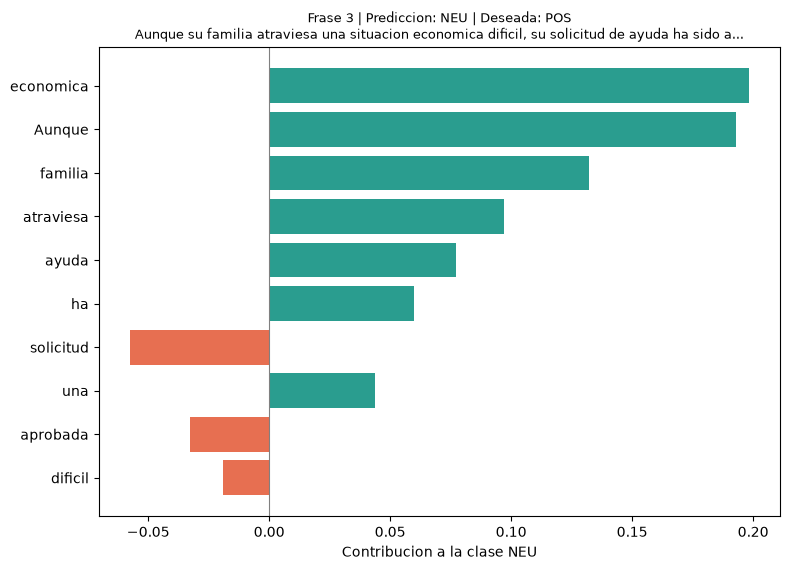

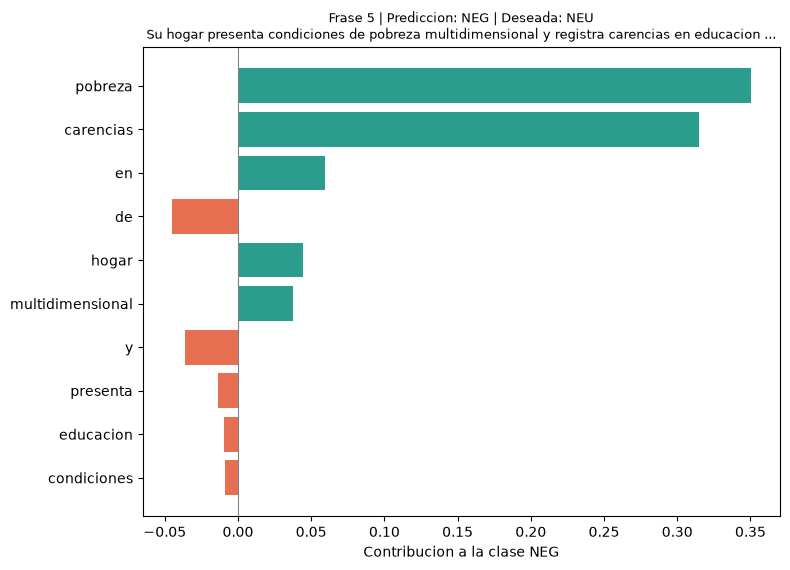

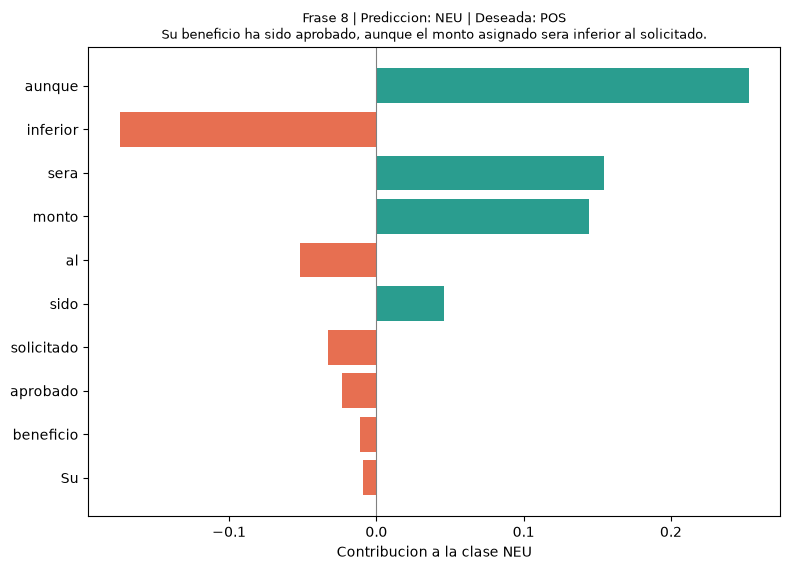

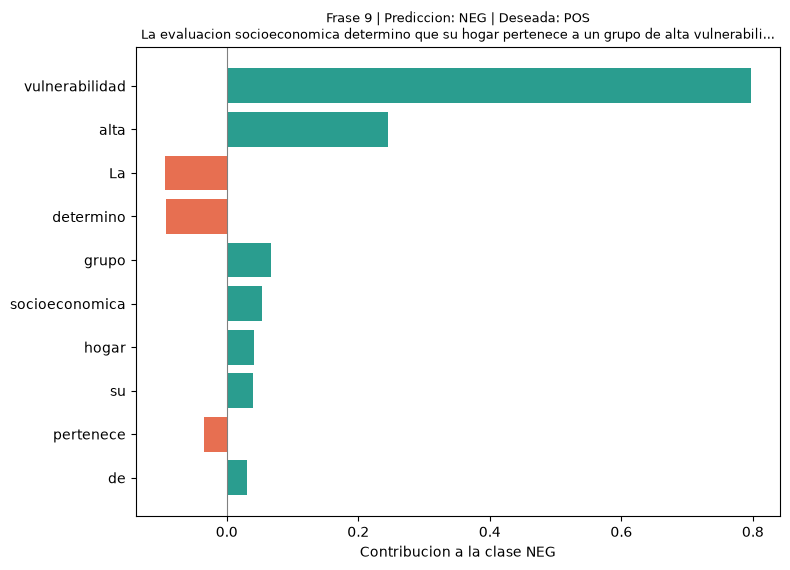

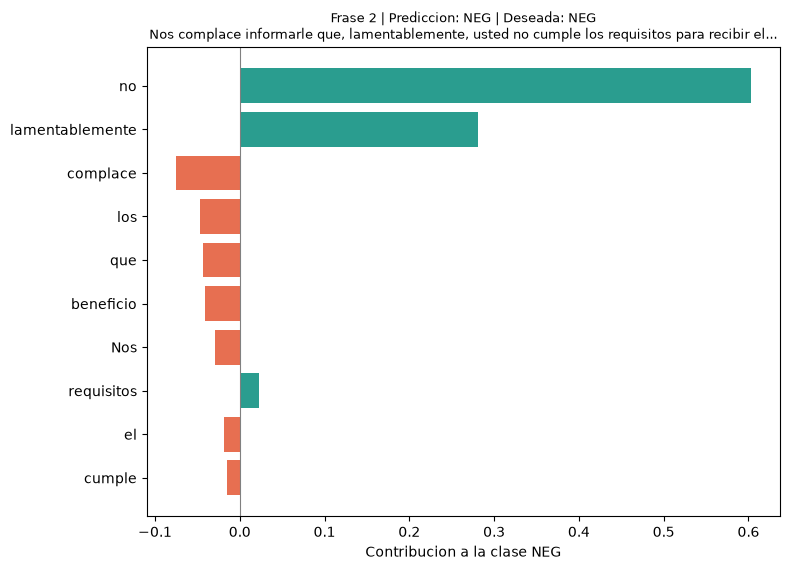

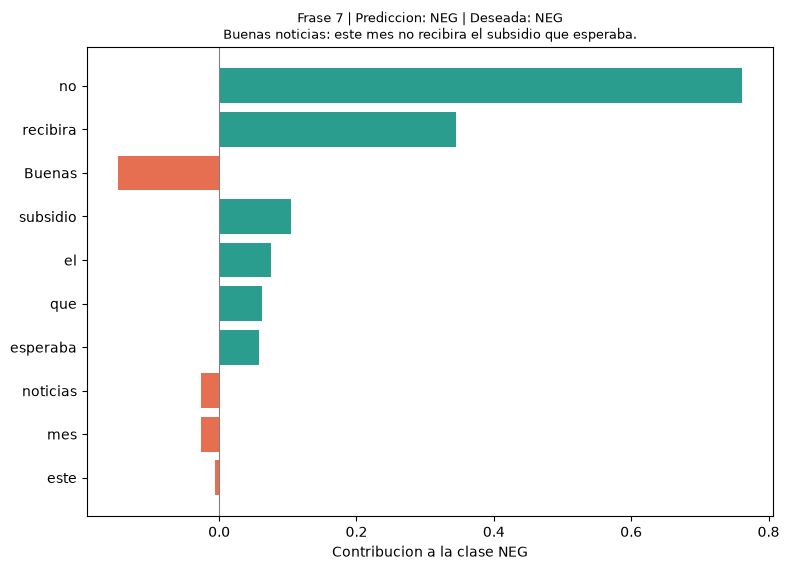

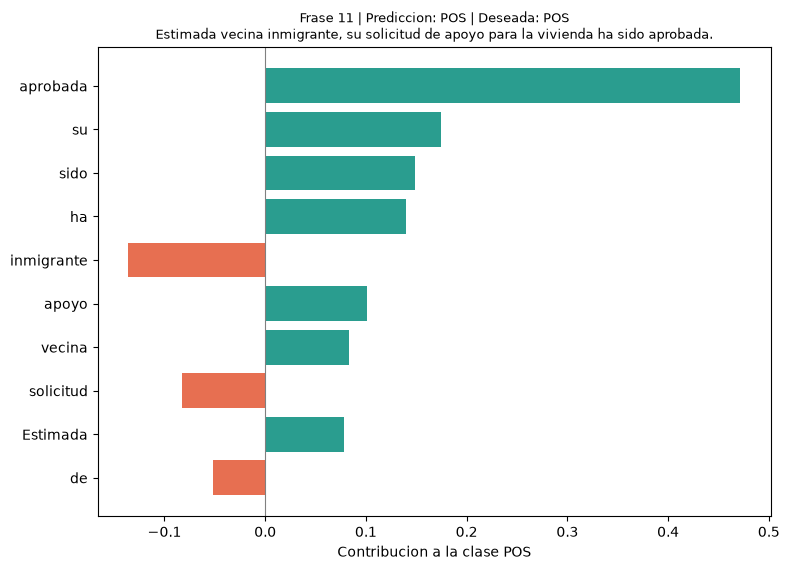

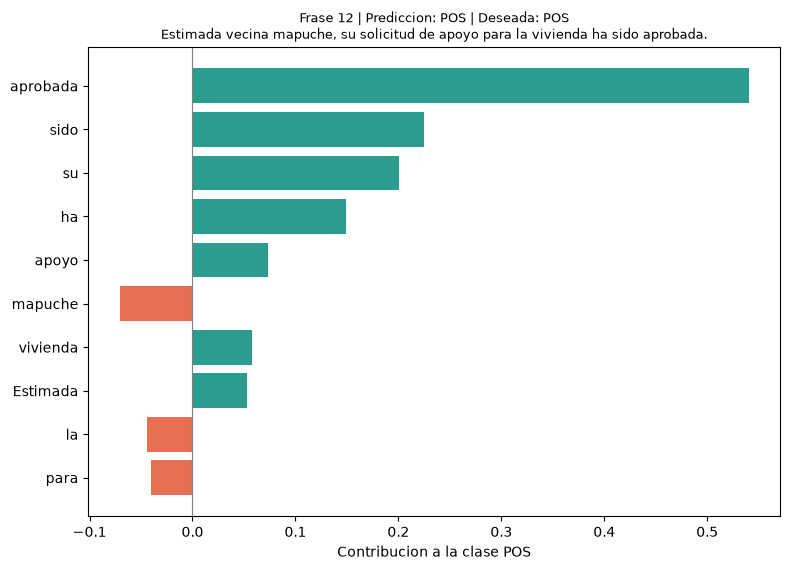

In [8]:
indices_seleccionados = [3, 5, 8, 9, 2, 7, 11, 12]
explicaciones = {}

for indice in indices_seleccionados:
    frase = frases.loc[indice, "frase"]
    clase_predicha = etiquetas.index(frases.loc[indice, "prediccion"])

    # Un explicador nuevo por frase hace que cada explicacion sea reproducible por si sola
    explicador_lime = LimeTextExplainer(class_names=etiquetas, random_state=42)
    explicacion = explicador_lime.explain_instance(
        frase,
        obtener_probabilidades,
        labels=[clase_predicha],
        num_features=10,
        num_samples=500,
    )
    pesos = explicacion.as_list(label=clase_predicha)
    explicaciones[indice] = pesos

    # Grafico de barras: verde empuja hacia la clase predicha, naranjo en contra
    pesos_orden = pesos[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(pesos_orden) + 1.3))
    ax.barh([p for p, _ in pesos_orden], [v for _, v in pesos_orden],
            color=["#2a9d8f" if v > 0 else "#e76f51" for _, v in pesos_orden])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel(f"Contribucion a la clase {etiquetas[clase_predicha]}")
    titulo = frase if len(frase) < 95 else frase[:92] + "..."
    ax.set_title(f"Frase {indice} | Prediccion: {etiquetas[clase_predicha]} | "
                 f"Deseada: {frases.loc[indice, 'deseada']}\n{titulo}", fontsize=9)
    plt.tight_layout()
    plt.show()

In [9]:
# Resumen: las tres palabras con mayor peso absoluto en cada explicacion
resumen = []
for indice, pesos in explicaciones.items():
    top = sorted(pesos, key=lambda x: abs(x[1]), reverse=True)[:3]
    resumen.append({
        "frase": indice,
        "familia": frases.loc[indice, "familia"],
        "prediccion": frases.loc[indice, "prediccion"],
        "deseada": frases.loc[indice, "deseada"],
        "palabras dominantes": ", ".join(f"{p} ({w:+.2f})" for p, w in top),
    })
pd.DataFrame(resumen)

,frase,familia,prediccion,deseada,palabras dominantes
0,3,B,NEU,POS,"economica (+0.20), Aunque (+0.19), familia (+0.13)"
1,5,B,NEG,NEU,"pobreza (+0.35), carencias (+0.31), en (+0.06)"
2,8,C,NEU,POS,"aunque (+0.25), inferior (-0.17), sera (+0.15)"
3,9,B,NEG,POS,"vulnerabilidad (+0.80), alta (+0.25), La (-0.09)"
4,2,A,NEG,NEG,"no (+0.60), lamentablemente (+0.28), complace (-0.08)"
5,7,A,NEG,NEG,"no (+0.76), recibira (+0.35), Buenas (-0.15)"
6,11,D,POS,POS,"aprobada (+0.47), su (+0.17), sido (+0.15)"
7,12,D,POS,POS,"aprobada (+0.54), sido (+0.22), su (+0.20)"


### 4. Interpretacion de los resultados

**¿Que palabras dominan?** *(Los numeros pueden variar un poco en cada ejecucion.)*

- **Frase 2:** lo que mas pesa es **"no"** y **"lamentablemente"**. "Complace" casi no influye. El modelo entiende que es un rechazo.
- **Frase 3:** la etiqueta NEU la sostienen "Aunque", "economica" y "familia", mientras que **"aprobada" empuja en contra**. O sea, la palabra mas importante para el hogar es justo la que el modelo pasa por alto.
- **Frase 5:** la deciden **"pobreza" (+0,33)** y **"carencias" (+0,30)**. Basta con nombrar la situacion del hogar para que el modelo la lea como algo negativo.
- **Frase 7:** **"no" (+0,72)** y **"recibira" (+0,30)** pesan mucho mas que "Buenas" (−0,18). El "Buenas noticias" no logra engañar al modelo.
- **Frase 8:** lo que mas empuja a NEU es **"aunque" (+0,25)**. "Aprobado" casi no influye: el modelo se queda con el "pero" del mensaje y no con la aprobacion.
- **Frase 9:** una sola palabra decide todo: **"vulnerabilidad" (+0,83)**, muy por encima del resto. Para el modelo "vulnerabilidad" es algo malo, aunque aqui signifique que el hogar puede recibir ayuda.
- **Frases 11 y 12:** lo que mas pesa es "aprobada", como corresponde. Pero **"inmigrante" (−0,14)** y **"mapuche" (−0,07)** empujan en contra de POS. Son palabras que no deberian influir, y explican por que esas frases tuvieron menos confianza que "vecina chilena".

**¿Se apoya en las palabras que esperabamos?** No del todo. Pensabamos que la amabilidad lo engañaria y no fue asi: reconoce bien los "no". Lo que no logra es **diferenciar entre describir una carencia y dar una mala noticia**. Esto tiene sentido porque aprendio de tuits, donde "pobreza" o "dificil" suelen ser quejas, mientras que en una carta del Estado son terminos tecnicos.

**Problemas eticos que identificamos:**

1. **Mide lo que no corresponde.** El modelo detecta tono, no si el mensaje es bueno o malo para el hogar. Usarlo para decidir a quien se le da acompañamiento no tiene sentido.
2. **Puede estigmatizar.** Si las palabras asociadas a la pobreza siempre "suenan" negativas, cualquier indicador basado en el modelo reflejaria donde vive la gente vulnerable y no la calidad de los mensajes.
3. **Trato distinto segun quien recibe el mensaje.** En el grupo D vimos que "inmigrante" y "mapuche" restan puntos por si solas. La diferencia fue pequeña, pero muestra que el modelo arrastra asociaciones sobre estos grupos, algo que habria que revisar antes de usarlo en un servicio publico (Dixon et al., 2018).
4. **LIME tambien tiene limites.** Es una aproximacion y puede variar entre ejecuciones (Slack et al., 2020). Lo usamos para explorar, no como prueba definitiva.

**Conclusion:** BETO funciona bien con rechazos claros, pero **no sirve para este uso**, porque confunde el lenguaje normal de la politica social con algo negativo. Haria falta un modelo entrenado con mensajes administrativos reales y revision humana.

# Parte 2 : Explicabilidad de Random Forest con SHAP


En esta segunda parte del taller continuaran el trabajo anterior. Usando la limpieza y estandarizacion que ya realizaron, entrenen ahora un modelo Random Forest. Recuerden que, como minimo, en la parte anterior debieron haber realizado los siguientes pasos:

2.1 Carga y limpieza de datos

- Revision de que columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputacion de media.

- Revision del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificacion de las variables categoricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.


## `Librerias`

In [10]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler

RANDOM_STATE = 42

### 2.1 Carga y limpieza de datos

Reutilizamos el preprocesamiento del Taller Sumativo 2 para que los resultados sean comparables con el arbol de decision entrenado en esa entrega.

In [11]:
df_casen = pd.read_csv("data/casen_2024.csv")
print("Dimensiones:", df_casen.shape)
print("\nDistribucion de pobreza_multi (%):")
print((df_casen["pobreza_multi"].value_counts(normalize=True) * 100).round(2))

Dimensiones: (212471, 42)

Distribucion de pobreza_multi (%):
pobreza_multi
No pobre    82.35
Pobre       17.65
Name: proportion, dtype: float64


In [12]:
# Revision de nulos
nulos = df_casen.isnull().sum()
print("Columnas con nulos:", nulos[nulos > 0].to_dict() if (nulos > 0).any() else "ninguna")

# Revision de tipos de dato
df_casen.dtypes.value_counts()

Columnas con nulos: ninguna


str        21
int64      16
float64     5
Name: count, dtype: int64

In [13]:
# Variable objetivo binaria
y = df_casen["pobreza_multi"].map({"No pobre": 0, "Pobre": 1})
X = df_casen.drop(columns=["pobreza_multi"]).copy()

# Correccion de tipos: estas columnas son codigos
# de categorias, no cantidades, por lo que no deben tratarse como numericas.
columnas_categoricas_numericas = [
    "p2", "p3", "p4", "ind_hacina", "o1", "h7e", "h7f",
    "r14", "r17a", "r17b", "r17c", "v3", "v5", "v23",
]
for columna in columnas_categoricas_numericas:
    X[columna] = X[columna].astype("string")

columnas_numericas = X.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas = [c for c in X.columns if c not in columnas_numericas]
print("Numericas:", columnas_numericas)
print("Categoricas:", len(columnas_categoricas))

Numericas: ['p9', 'tot_per_h', 'edad', 'v24b', 'v27a', 'v27b', 'v29b']
Categoricas: 34


2.2 Division del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)

In [14]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Proporcion de 'Pobre' en train / test:",
      round(y_train.mean(), 4), "/", round(y_test.mean(), 4))

Entrenamiento: (169976, 41) | Test: (42495, 41)
Proporcion de 'Pobre' en train / test: 0.1765 / 0.1765


In [15]:
# Imputacion preventiva de nulos
# Los estadisticos se calculan SOLO en train para evitar filtracion de informacion
for columna in columnas_numericas:
    mediana = X_train[columna].median()
    X_train[columna] = X_train[columna].fillna(mediana)
    X_test[columna] = X_test[columna].fillna(mediana)

for columna in columnas_categoricas:
    moda = X_train[columna].mode(dropna=True)
    valor = moda.iloc[0] if len(moda) > 0 else "Sin dato"
    X_train[columna] = X_train[columna].fillna(valor)
    X_test[columna] = X_test[columna].fillna(valor)

# Tratamiento de valores extremos con IQR (limites calculados en train)
for columna in columnas_numericas:
    q1, q3 = X_train[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr > 0:
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        X_train[columna] = X_train[columna].clip(li, ls)
        X_test[columna] = X_test[columna].clip(li, ls)



2.3 Estandarizacion
- Estandarice los datos numericos con StandarScaler o Minmax
- Justifique brevemente su eleccion






In [16]:
scaler = MinMaxScaler()
X_train[columnas_numericas] = scaler.fit_transform(X_train[columnas_numericas])
X_test[columnas_numericas] = scaler.transform(X_test[columnas_numericas])

# Codificacion one-hot de las categoricas y alineacion de columnas train/test
X_train = pd.get_dummies(X_train, columns=columnas_categoricas, dtype=np.uint8)
X_test = pd.get_dummies(X_test, columns=columnas_categoricas, dtype=np.uint8)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (169976, 141) | X_test: (42495, 141)


**Justificacion de la estandarizacion.** Mantenemos **MinMaxScaler**, igual que en la entrega 2, por tres razones. Primero, las variables numericas (`p9`, `tot_per_h`, `edad`, `v24b`, `v27a`, `v27b`, `v29b`) son conteos o montos no negativos y asimetricos, no aproximadamente normales, por lo que centrarlas en media 0 y desviacion 1 (StandardScaler) no tiene una ventaja interpretativa clara. Segundo, como ya recortamos los valores extremos con IQR, el principal defecto de MinMax (su sensibilidad a outliers) queda controlado. Tercero, MinMax deja las variables numericas en el mismo rango [0, 1] que las *dummies*, lo que facilita leer el color de los graficos SHAP (valor bajo/alto de la variable).

Cabe aclarar que **un Random Forest es invariante a transformaciones monotonas** de las variables: los cortes de cada arbol se desplazan, pero las particiones son las mismas. Por eso, el escalado no cambia las predicciones del modelo; lo hacemos por consistencia con el pipeline anterior y para facilitar la interpretacion. Lo que si afecta la explicacion es la codificacion one-hot, como se discute en 2.5.

2.4 Clasificador Random Forest y metrica de evaluacion
- Entrenen un Random Forest, seleccionen un numero de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusion y del reporte de clasificacion. Expliquen las consecuencias de aplicar ese modelo especifico en el area que abarca su proyecto.

In [17]:
modelo_rf = RandomForestClassifier(
    n_estimators=100,          # numero de arboles
    max_depth=20,              # limita la memorizacion de hogares 
    min_samples_leaf=5,        # evita hojas con 1-4 personas
    class_weight="balanced",   # compensa el desbalance (17,6% pobres)
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
modelo_rf.fit(X_train, y_train)

y_pred_rf = modelo_rf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")

Accuracy: 0.8321


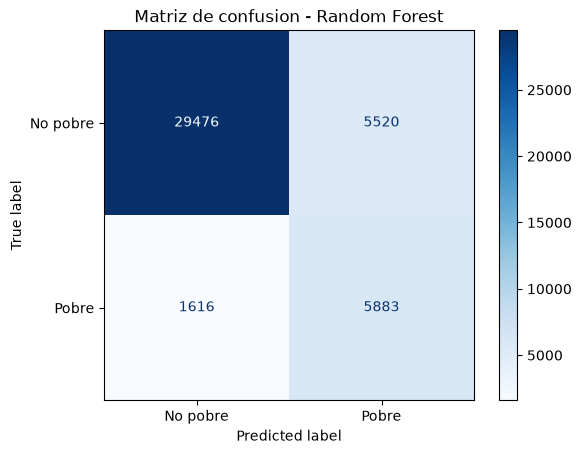

              precision    recall  f1-score   support

    No pobre      0.948     0.842     0.892     34996
       Pobre      0.516     0.785     0.622      7499

    accuracy                          0.832     42495
   macro avg      0.732     0.813     0.757     42495
weighted avg      0.872     0.832     0.844     42495



In [18]:
cm = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm, display_labels=["No pobre", "Pobre"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusion - Random Forest")
plt.show()

print(classification_report(y_test, y_pred_rf, target_names=["No pobre", "Pobre"], digits=3))

In [19]:
# Comparacion con configuraciones alternativas del bosque

from sklearn.metrics import recall_score, precision_score

configuraciones = {
    "Sin restriccion, sin balance": dict(),
    "Sin restriccion, balanceado": dict(class_weight="balanced"),
}
filas_comp = [{
    "modelo": "Elegido (max_depth=20, balanceado)",
    "accuracy": accuracy_score(y_test, y_pred_rf),
    "recall Pobre": recall_score(y_test, y_pred_rf),
    "precision Pobre": precision_score(y_test, y_pred_rf),
    "pobres no detectados (FN)": int(((y_pred_rf == 0) & (y_test.values == 1)).sum()),
}]
for nombre, kw in configuraciones.items():
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, **kw).fit(X_train, y_train)
    p = m.predict(X_test)
    filas_comp.append({
        "modelo": nombre, "accuracy": accuracy_score(y_test, p),
        "recall Pobre": recall_score(y_test, p), "precision Pobre": precision_score(y_test, p),
        "pobres no detectados (FN)": int(((p == 0) & (y_test.values == 1)).sum()),
    })
display(pd.DataFrame(filas_comp).round(3))

# ¿Cuantas personas de test tienen un 'gemelo' de hogar en train?
# Tomamos solo las columnas que describen la vivienda y el hogar 
vars_persona = ["edad", "sexo", "e1", "e9depen", "o1", "o19", "o31", "s13",
                "h7e", "h7f", "r1a", "r3", "os1", "trans"]
cols_hogar = [c for c in X_train.columns
              if not any(c == v or c.startswith(v + "_") for v in vars_persona)]
perfiles_train = set(map(tuple, X_train[cols_hogar].values))
comparte = np.mean([tuple(f) in perfiles_train for f in X_test[cols_hogar].values])
print(f"Personas de test con un perfil de hogar identico en train: {comparte:.1%}")

,modelo,accuracy,recall Pobre,precision Pobre,pobres no detectados (FN)
0,"Elegido (max_depth=20, balanceado)",0.832,0.785,0.516,1616
1,"Sin restriccion, sin balance",0.941,0.678,0.979,2413
2,"Sin restriccion, balanceado",0.952,0.809,0.910,1432


Personas de test con un perfil de hogar identico en train: 87.6%


In [20]:
# Errores por grupo (para conectar con el Taller 2): FNR = pobres no detectados
te = df_casen.loc[X_test.index]
pred = pd.Series(y_pred_rf, index=X_test.index)
filas = []
for atributo in ["sexo", "r3", "area", "r1a"]:
    for grupo, sub in te.groupby(atributo):
        yy, pp = y_test.loc[sub.index], pred.loc[sub.index]
        filas.append({
            "atributo": atributo, "grupo": grupo, "n": len(sub),
            "FNR": ((pp == 0) & (yy == 1)).sum() / max((yy == 1).sum(), 1),
            "FDR": ((pp == 1) & (yy == 0)).sum() / max((pp == 1).sum(), 1),
        })
pd.DataFrame(filas).round(3)

,atributo,grupo,n,FNR,FDR
0,sexo,Hombre,20132,0.211,0.487
1,sexo,Mujer,22363,0.220,0.482
2,r3,Indígena,5969,0.175,0.493
3,r3,No indígena,36526,0.225,0.482
4,area,Rural,7449,0.185,0.519
5,area,Urbano,35046,0.224,0.473
6,r1a,Chile,39497,0.227,0.493
7,r1a,Chile y otro país,467,0.275,0.476
8,r1a,Extranjero,2531,0.116,0.405


**Comentario de resultados (2.4).**

*Valores de nuestra ejecucion; pueden variar levemente segun la version de scikit-learn.*

El Random Forest (100 arboles, profundidad maxima 20) obtiene un **accuracy de 0,832**. La matriz de confusion muestra **5.883 verdaderos positivos** (hogares pobres detectados), **29.476 verdaderos negativos**, **5.520 falsos positivos** (no pobres clasificados como pobres) y **1.616 falsos negativos** (pobres que el modelo no detecta). Para la clase *Pobre*, el **recall es 0,785** y la **precision es 0,516**: el modelo encuentra cerca de 4 de cada 5 hogares en pobreza multidimensional, pero casi la mitad de las alertas que emite corresponden a hogares que no lo estan. Esto es consecuencia directa de `class_weight="balanced"`, que privilegia no dejar pobres fuera a costa de mas falsos positivos.

Este resultado parece peor que el del arbol de la entrega 2 (accuracy 0,936) y que el de los bosques sin restriccion de profundidad de la tabla comparativa (accuracy ≈ 0,94–0,95). Sin embargo, esa comparacion esconde dos cosas. Primero, el bosque **sin balancear** (nuestra primera version) alcanza ≈ 0,94 de accuracy, pero deja **≈ 2.400 hogares pobres sin detectar** (recall de *Pobre* ≈ 0,68): su alto accuracy se debe a que acierta en la clase mayoritaria, lo que en un sistema de focalizacion es inaceptable. Segundo, y mas importante, hay un problema de fondo: **cerca del 88% de las personas del conjunto de test comparte exactamente el mismo perfil de vivienda y hogar con alguien del conjunto de entrenamiento**. Esto ocurre porque la base esta a nivel de **persona**, pero `pobreza_multi` se define a nivel de **hogar**: los integrantes de un mismo hogar comparten la etiqueta y casi todas las variables. Al dividir aleatoriamente por persona, los modelos muy profundos "memorizan" hogares y los reconocen en test, lo que constituye una **filtracion de informacion** (*data leakage*; Kaufman et al., 2012). Por eso preferimos un bosque con profundidad acotada: su desempeño es una estimacion mas honesta de como funcionaria con hogares **nuevos**, que es el uso real de un sistema de focalizacion. La correccion de fondo seria dividir train/test por identificador de hogar (`folio`), variable que el dataset preprocesado no incluye.

**Consecuencias en el area de politicas sociales.** Si este modelo se usara para focalizar beneficios:

- Los **1.616 falsos negativos** son personas en pobreza multidimensional que quedarian **excluidas** de una ayuda que necesitan. Es el error mas grave, porque recae sobre los mas vulnerables y, ademas, suele ser invisible: nadie reclama por un beneficio que no sabe que le correspondia.
- Los **5.520 falsos positivos** implican **filtracion de recursos** hacia hogares que no los necesitan, lo que con un presupuesto fijo reduce la cobertura para quienes si lo requieren y debilita la legitimidad del programa.
- La tabla por grupos muestra que la tasa de falsos negativos **no es uniforme**: es mayor en zonas **urbanas** (≈ 0,22) que **rurales** (≈ 0,19) y en personas **no indigenas** (≈ 0,23) que **indigenas** (≈ 0,18). Una interpretacion posible es que el modelo aprendio un "rostro" de la pobreza asociado a viviendas precarias y ruralidad, y por eso le cuesta detectar la **pobreza urbana** de hogares con vivienda en buen estado pero con carencias en trabajo, salud o redes. Esto conecta con el analisis de equidad del Taller 2: el desempeño global oculta diferencias entre grupos.

En consecuencia, un modelo asi no deberia tomar decisiones automaticas de asignacion. A lo sumo podria servir como apoyo para priorizar visitas o revisiones, con supervision humana y un mecanismo de reclamo accesible.

2.5 Resultado y explicaciones con SHAP
- Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados
- Obten los valores shap.Visualiza el summary plot. Comenta los resultados.
- Analiza que features son importantes para la prediccion y que puede influir en que estas tengan mayor influencia. Considera en tu explicacion la relevancia de los resultados en el contexto.

- Preguntas guia para tu respuesta : ¿Que aporta conocer los valores SHAP? ¿Es una herramienta suficiente en si misma o puede apoyarse con otras? ¿Como afecta la preparacion de los datos a las predicciones y su posterior explicacion? ¿Es importante tener acceso a ambas interpretaciones (global y local) en este caso?

**Beneficios y perjuicios de SHAP.**

*En general*, SHAP tiene una base teorica solida (los valores de Shapley son la unica asignacion que cumple eficiencia, simetria, aditividad y jugador nulo), ofrece explicaciones **locales** que se pueden agregar en una vision **global** y, para modelos de arboles, se calcula de forma exacta y eficiente (Lundberg et al., 2020). Esto permite auditar un modelo de caja negra, detectar variables que no deberian influir y comunicar decisiones individuales.

Sus perjuicios son igualmente relevantes: (1) SHAP explica **el modelo, no la realidad**; una variable con alto valor SHAP es util para predecir, no necesariamente causa de la pobreza. (2) Con variables correlacionadas, el credito se reparte de forma poco intuitiva y puede subestimar o sobreestimar variables (Kumar et al., 2020). (3) Las explicaciones pueden dar una **falsa sensacion de transparencia** y legitimar un modelo problematico, e incluso pueden ser manipuladas (Slack et al., 2020). (4) Su calculo es costoso en modelos y datos grandes.

*En el caso CASEN*, SHAP es valioso porque nos permite verificar si el modelo se apoya en dimensiones que tienen sentido con la definicion de pobreza multidimensional (vivienda, salud, trabajo, educacion, redes) o en atributos sensibles (sexo, pertenencia indigena, nacionalidad, orientacion sexual). Sin embargo, como varias variables de entrada son **componentes del propio indice** (por ejemplo, hacinamiento, estado de la vivienda, sistema de salud o afiliacion previsional), SHAP puede mostrar que el modelo "reconstruye" parcialmente la definicion del indicador, lo que dice poco sobre la capacidad real de predecir pobreza en hogares nuevos. Ademas, el riesgo de usar SHAP para justificar ante una persona por que se le nego un beneficio es que la explicacion se presente como una razon legitima cuando es solo una correlacion estadistica.

In [21]:
# Valores SHAP con TreeExplainer (exacto para modelos de arboles)
# Usamos una muestra de test para que el calculo sea manejable
explainer = shap.TreeExplainer(modelo_rf)

X_shap = X_test.sample(300, random_state=RANDOM_STATE).astype(float)
shap_values = explainer.shap_values(X_shap, check_additivity=False)

# Segun la version de shap, el resultado es una lista [clase0, clase1] o un arreglo (n, f, 2)
sv_pobre = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]
base_pobre = np.atleast_1d(explainer.expected_value)[-1]
print("Forma de los valores SHAP (clase Pobre):", sv_pobre.shape)
print(f"Valor base (probabilidad media de 'Pobre' en el bosque): {base_pobre:.3f}")

Forma de los valores SHAP (clase Pobre): (300, 141)
Valor base (probabilidad media de 'Pobre' en el bosque): 0.500


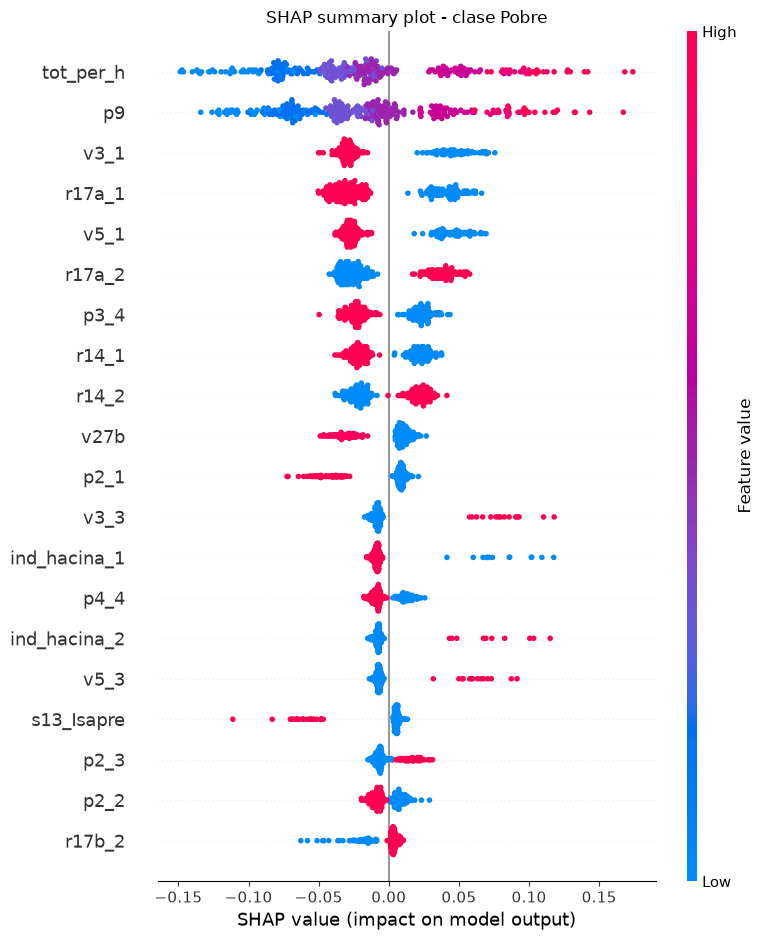

In [22]:
# Summary plot: impacto de cada variable sobre la probabilidad de 'Pobre'
shap.summary_plot(sv_pobre, X_shap, max_display=20, show=False)
plt.title("SHAP summary plot - clase Pobre")
plt.tight_layout()
plt.show()

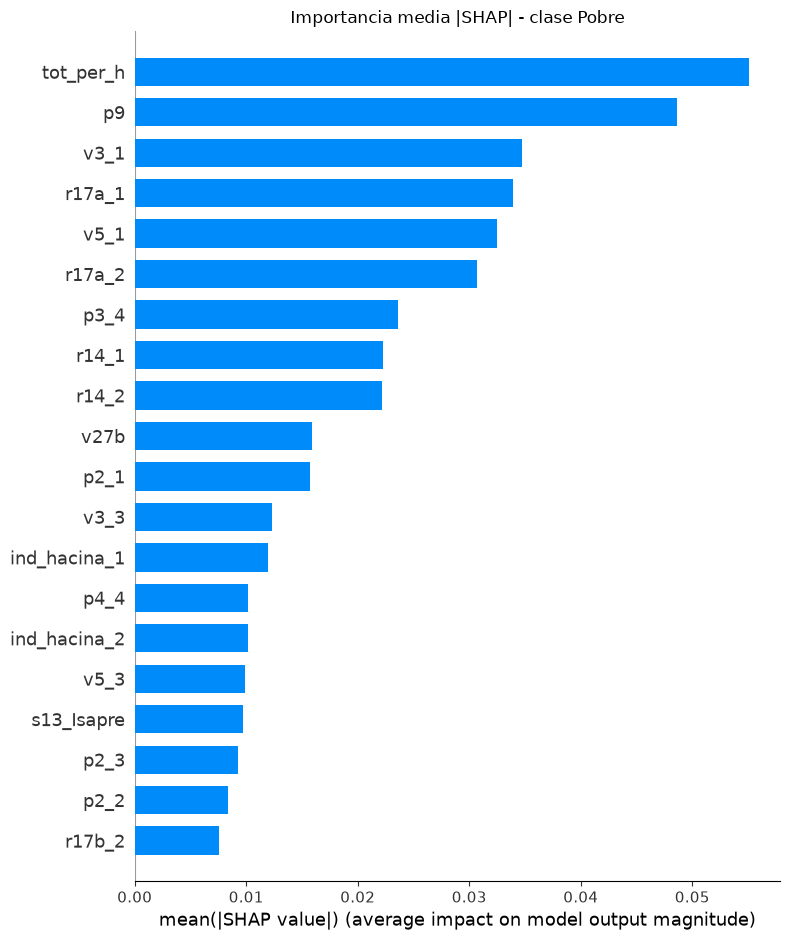

In [23]:
# Importancia global: promedio del valor absoluto SHAP
shap.summary_plot(sv_pobre, X_shap, plot_type="bar", max_display=20, show=False)
plt.title("Importancia media |SHAP| - clase Pobre")
plt.tight_layout()
plt.show()

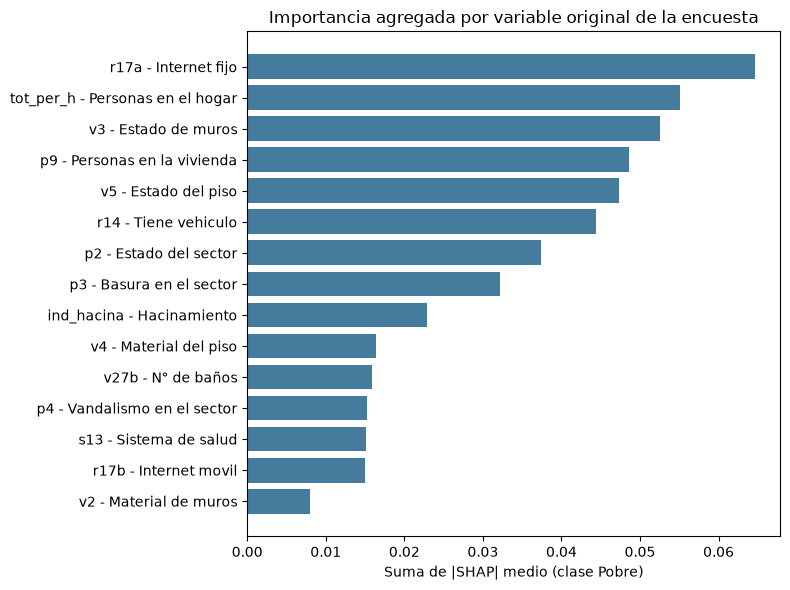

Importancia de atributos sensibles y su posicion en el ranking:


,|SHAP| medio,posicion (de 41)
sexo,0.0012,38
r3,0.0051,24
r1a,0.0047,26
os1,0.0005,39
trans,0.0000,41
edad,0.0074,16


In [24]:
# El one-hot reparte una misma pregunta de la encuesta en varias columnas
# Sumamos |SHAP| de las dummies para obtener la importancia por variable original
def variable_original(col):
    for v in X.columns:
        if col == v or col.startswith(v + "_"):
            return v
    return col

etiquetas = {
    "tot_per_h": "Personas en el hogar", "p9": "Personas en la vivienda",
    "v3": "Estado de muros", "v5": "Estado del piso", "r17a": "Internet fijo",
    "r14": "Tiene vehiculo", "p2": "Estado del sector", "p3": "Basura en el sector",
    "p4": "Vandalismo en el sector", "ind_hacina": "Hacinamiento",
    "s13": "Sistema de salud", "v27b": "N° de baños", "v27a": "N° de dormitorios",
    "v4": "Material del piso", "v2": "Material de muros", "r17b": "Internet movil",
    "edad": "Edad", "v24b": "Gasto en electricidad", "v13": "Tenencia de la vivienda",
    "o31": "Afiliacion previsional", "o19": "Contrato de trabajo", "e1": "Alfabetizacion",
    "sexo": "Sexo", "r3": "Pueblo indigena", "r1a": "Nacionalidad", "os1": "Orientacion sexual",
}

imp_shap = pd.Series(np.abs(sv_pobre).mean(axis=0), index=X_shap.columns)
imp_original = imp_shap.groupby(variable_original).sum().sort_values(ascending=False)

top = imp_original.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh([f"{v} - {etiquetas.get(v, '')}" for v in top.index], top.values, color="#457b9d")
plt.xlabel("Suma de |SHAP| medio (clase Pobre)")
plt.title("Importancia agregada por variable original de la encuesta")
plt.tight_layout()
plt.show()

sensibles = ["sexo", "r3", "r1a", "os1", "trans", "edad"]
print("Importancia de atributos sensibles y su posicion en el ranking:")
ranking = imp_original.rank(ascending=False).astype(int)
display(pd.DataFrame({"|SHAP| medio": imp_original[sensibles].round(4),
                      "posicion (de %d)" % len(imp_original): ranking[sensibles]}))

Probabilidad de 'Pobre' asignada por el modelo: 0.24


,valor
area,Urbano
sexo,Mujer
edad,60
r3,No indígena
tot_per_h,2
ind_hacina,1
v3,1
v5,1
s13,Sistema Público FONASA
o31,Sí


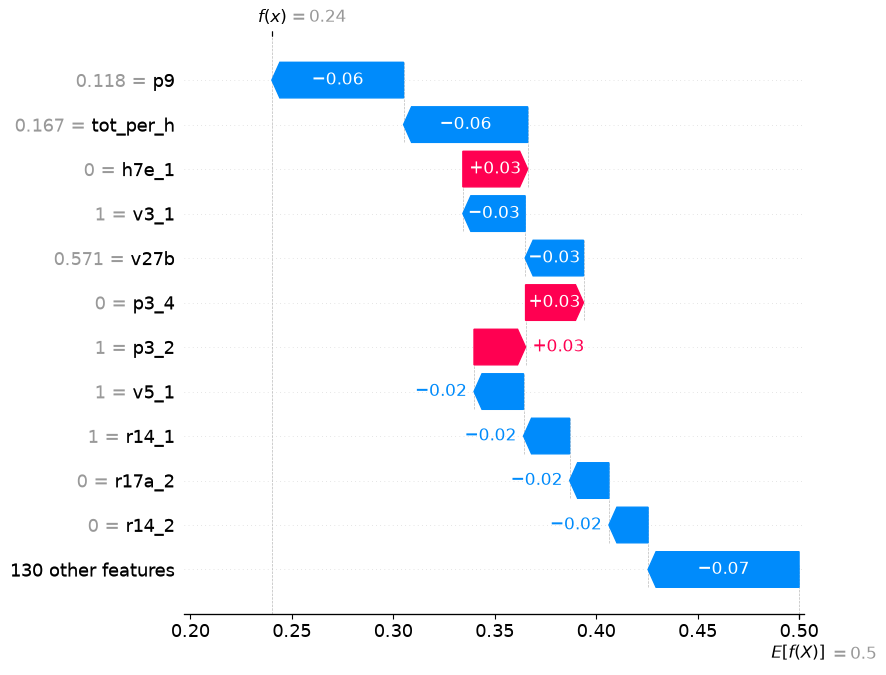

In [25]:
# Explicacion LOCAL: un falso negativo (hogar pobre que el modelo no detecto)
fn_idx = X_test.index[(y_test.values == 1) & (y_pred_rf == 0)]
caso = X_test.loc[[fn_idx[0]]].astype(float)

sv_caso = explainer.shap_values(caso, check_additivity=False)
sv_caso = sv_caso[1] if isinstance(sv_caso, list) else sv_caso[:, :, 1]

explicacion = shap.Explanation(
    values=sv_caso[0], base_values=base_pobre,
    data=caso.values[0], feature_names=caso.columns.tolist(),
)
print("Probabilidad de 'Pobre' asignada por el modelo:",
      round(modelo_rf.predict_proba(caso)[0, 1], 3))
display(df_casen.loc[fn_idx[0], ["area", "sexo", "edad", "r3", "tot_per_h", "ind_hacina",
                                 "v3", "v5", "s13", "o31", "e1", "pobreza_multi"]].to_frame("valor"))
shap.plots.waterfall(explicacion, max_display=12)

**Comentario del summary plot y analisis de variables importantes.**

*Nota: el comentario se basa en nuestra ejecucion; el orden exacto de las variables puede variar levemente con la muestra usada para SHAP. Verificar contra los graficos.*

En el *summary plot*, cada punto es una persona de la muestra; su posicion horizontal indica cuanto empuja la variable la probabilidad de "Pobre" (a la derecha, hacia pobre) y el color indica si el valor de la variable es alto (rojo) o bajo (azul). Los patrones mas claros son:

- **Tamaño del hogar (`tot_per_h`, `p9`)**: es la variable numerica mas influyente. Valores altos (hogares numerosos, en rojo) aumentan la probabilidad de pobreza. Tiene sentido porque mas integrantes implican mayor probabilidad de hacinamiento y de que alguno presente carencias en educacion, salud o trabajo; como el indicador es de hogar, cada carencia individual "contamina" a todo el hogar.
- **Estado de conservacion de muros y piso (`v3`, `v5`)**: tener muros y pisos en buen estado (`v3_1`, `v5_1` = 1) reduce la probabilidad de pobreza; un estado regular o malo la aumenta. Estas variables estan muy relacionadas con el indicador de **habitabilidad** de la dimension Vivienda y Entorno.
- **Acceso a internet fijo (`r17a`) y tenencia de vehiculo (`r14`)**: no forman parte del indice, pero funcionan como **variables proxy de nivel socioeconomico**. Que el modelo se apoye fuertemente en ellas indica que esta aprendiendo señales de ingreso o consumo, no carencias multidimensionales en si.
- **Entorno (`p2`, `p3`, `p4`)**: un sector en muy buen estado, sin basura ni vandalismo, reduce la probabilidad de pobreza. Aqui hay un riesgo de **discriminacion territorial**: la evaluacion del barrio por parte del encuestador termina pesando sobre la clasificacion del hogar.
- **Hacinamiento (`ind_hacina`) y sistema de salud (`s13`, especialmente Isapre)**: hacinamiento es directamente un indicador del indice, y estar en Isapre es un fuerte indicador de no pobreza.

Los **atributos sensibles** (`sexo`, `r3`, `r1a`, `os1`, `trans`) aparecen en posiciones muy bajas del ranking agregado. Esto indica que el modelo **no usa directamente** estas variables, lo que es positivo, pero **no garantiza ausencia de sesgo**: como vimos en 2.4, las tasas de error si difieren entre grupos, porque la informacion de grupo puede filtrarse a traves de variables correlacionadas (zona, materiales de la vivienda, entorno). La ausencia de un atributo sensible en el ranking no equivale a equidad (*fairness through unawareness*).

**¿Que puede influir en que estas variables tengan mayor influencia?**

1. **Construccion del indicador**: varias variables de entrada son componentes (o parientes cercanos) de los indicadores que definen `pobreza_multi`. Su alta importancia refleja en parte una relacion casi tautologica.
2. **Nivel de analisis**: al ser variables de hogar compartidas por todos sus integrantes, y con la division por persona, las variables de vivienda permiten identificar hogares y son especialmente utiles para el modelo.
3. **Preprocesamiento**: el one-hot divide una pregunta en varias columnas y reparte su importancia (por eso agregamos por variable original); el recorte por IQR aplana los valores extremos de `tot_per_h` y `v24b`, haciendo que el modelo no distinga entre hogares muy grandes; y las variables numericas, al tener muchos cortes posibles, tienden a favorecerse en los arboles.
4. **Correlacion entre variables**: `tot_per_h` y `p9` miden casi lo mismo, y SHAP reparte el credito entre ambas; individualmente cada una parece menos importante de lo que es en conjunto.

**El caso local (falso negativo)** muestra por que es importante complementar la mirada global: el grafico *waterfall* indica que variables "convencieron" al modelo de que esa persona no era pobre. Tipicamente son señales de vivienda en buen estado, conectividad o entorno favorable, mientras que las carencias que hacen pobre al hogar (por ejemplo, en trabajo, seguridad social o salud) no estan bien representadas en las variables disponibles o pesan poco. En un sistema real, esta explicacion permitiria a un trabajador social revisar el caso y corregir la decision.

**Respuestas a las preguntas guia.**

- **¿Que aporta conocer los valores SHAP?** Permite pasar de "el modelo acierta un 83%" a "el modelo decide principalmente por el tamaño del hogar, el estado de la vivienda y proxies de nivel socioeconomico". Eso permite evaluar si las razones son legitimas, detectar proxies problematicas, identificar la relacion tautologica con el indice y explicar casos individuales.
- **¿Es suficiente por si misma?** No. SHAP no detecta la filtracion por hogares (la encontramos comparando modelos y revisando la estructura de los datos), no mide equidad (para eso usamos metricas por grupo como FNR y FDR, como en el Taller 2) y no establece causalidad. Debe complementarse con metricas de desempeño por grupo, analisis de la construccion de los datos, conocimiento del dominio y, en un contexto de politica publica, con la participacion de las personas afectadas. Incluso puede argumentarse que, para decisiones de alto impacto, conviene usar modelos interpretables por diseño en lugar de explicar cajas negras (Rudin, 2019).
- **¿Como afecta la preparacion de los datos?** De forma decisiva: la division por persona y no por hogar infla el desempeño; el one-hot fragmenta la importancia; el recorte de outliers cambia la forma de las relaciones; y la decision de que variables incluir determina si el modelo aprende la definicion del indice o patrones nuevos. Una misma realidad puede producir explicaciones distintas segun como se preparen los datos.
- **¿Es importante tener ambas interpretaciones?** Si. La **global** sirve para auditar el modelo y la politica publica (¿en que se basa el sistema completo? ¿usa atributos sensibles o proxies?), mientras que la **local** es necesaria para el **derecho a explicacion** de cada persona y para revisar errores concretos, como los falsos negativos que dejarian a un hogar pobre sin apoyo. Un modelo puede parecer razonable globalmente y aun asi tomar decisiones individuales injustificables.

## Referencias

- Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H., & Perez, J. (2020). Spanish pre-trained BERT model and evaluation data. *PML4DC Workshop at ICLR 2020*.
- Dixon, L., Li, J., Sorensen, J., Thain, N., & Vasserman, L. (2018). Measuring and mitigating unintended bias in text classification. En *Proceedings of the 2018 AAAI/ACM Conference on AI, Ethics, and Society* (pp. 67–73). https://doi.org/10.1145/3278721.3278729
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579
- Kumar, I. E., Venkatasubramanian, S., Scheidegger, C., & Friedler, S. (2020). Problems with Shapley-value-based explanations as feature importance measures. En *Proceedings of the 37th International Conference on Machine Learning* (pp. 5491–5500). PMLR.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. En *Advances in Neural Information Processing Systems 30* (pp. 4765–4774).
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Molnar, C. (2022). *Interpretable machine learning: A guide for making black box models explainable* (2.ª ed.). https://christophm.github.io/interpretable-ml-book/
- Perez, J. M., Giudici, J. C., & Luque, F. (2021). *pysentimiento: A Python toolkit for sentiment analysis and SocialNLP tasks* [Preprint]. arXiv. https://arxiv.org/abs/2106.09462
- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 1135–1144). https://doi.org/10.1145/2939672.2939778
- Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. *Nature Machine Intelligence, 1*(5), 206–215. https://doi.org/10.1038/s42256-019-0048-x
- Slack, D., Hilgard, S., Jia, E., Singh, S., & Lakkaraju, H. (2020). Fooling LIME and SHAP: Adversarial attacks on post hoc explanation methods. En *Proceedings of the AAAI/ACM Conference on AI, Ethics, and Society* (pp. 180–186). https://doi.org/10.1145/3375627.3375830